# Importing Necessary Libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
wines = pd.read_csv('wines.csv')

# Information about the dataset

In [7]:
wines.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [9]:
wines.shape

(150, 5)

In [11]:
wines.columns


Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

In [13]:
wines.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


# Missing Values

In [15]:
wines.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

# Descriptive Statistics

In [17]:
wines.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


# Check the distribution of species

In [21]:
wines['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

# Visualize feature relationships

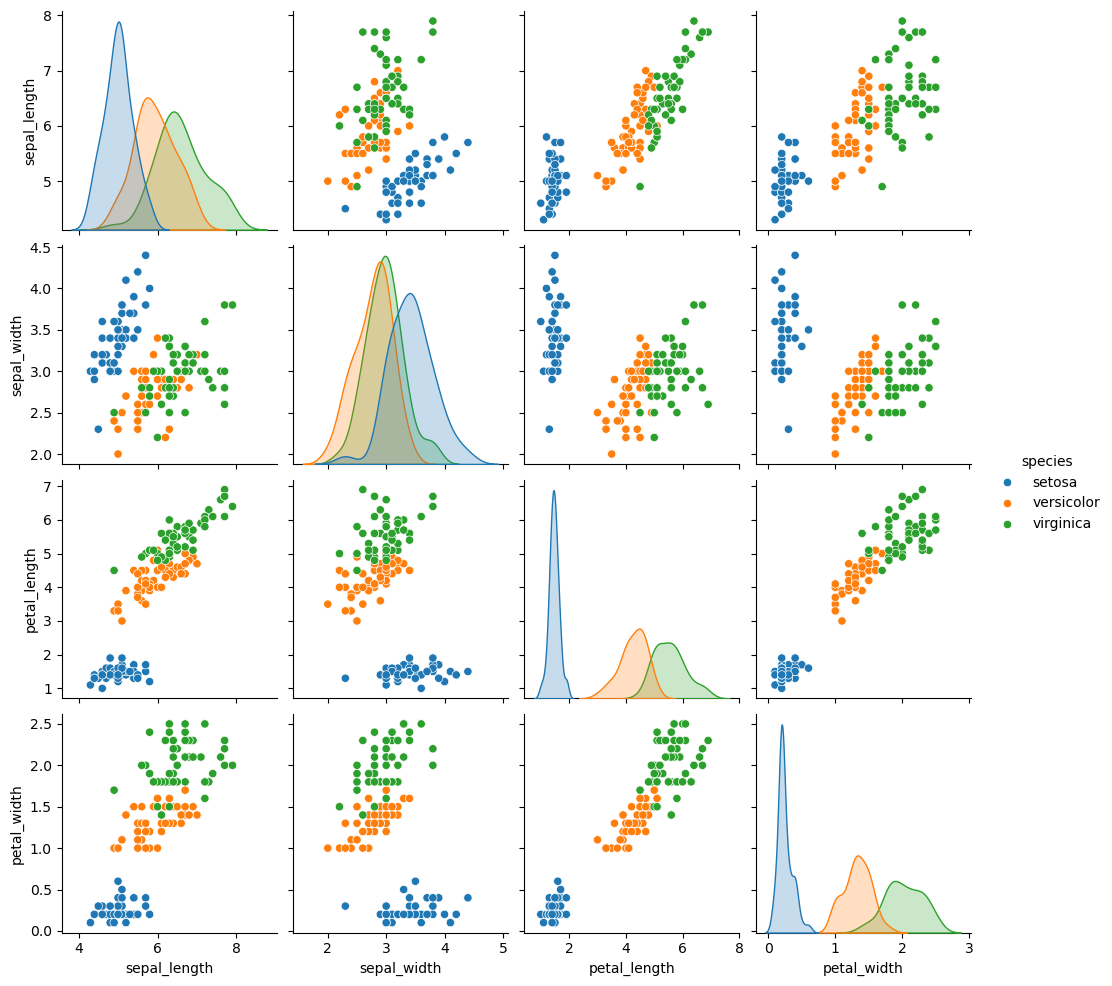

In [23]:
sns.pairplot(wines, hue='species')
plt.show()

# Separate features and target

In [25]:
X = wines.drop('species', axis=1)

y = wines['species']

In [27]:
print(X.head())
print(y.head())

   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


# Split the dataset (80/20)

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [31]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


# Feature scaling using StandardScaler

In [33]:
from sklearn.preprocessing import StandardScaler

In [35]:
scaler = StandardScaler()

In [37]:
X_train_scaled = scaler.fit_transform(X_train)

In [39]:
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression

In [41]:
from sklearn.linear_model import LogisticRegression

In [43]:
log_model = LogisticRegression(max_iter=1000)

In [45]:
log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [47]:
log_predictions = log_model.predict(X_test_scaled)

In [51]:
print(log_predictions[:10])

['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


# Train Decision Tree

In [53]:
from sklearn.tree import DecisionTreeClassifier

In [55]:
tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=3
)

In [57]:
tree_model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [59]:
tree_predictions = tree_model.predict(X_test_scaled)

# Evaluate model performance

In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [63]:
def evaluate_model(y_test, predictions, model_name):

    print("Model:", model_name)

    print("Accuracy:",
          accuracy_score(y_test, predictions))

    print("Precision:",
          precision_score(y_test, predictions, average='macro'))

    print("Recall:",
          recall_score(y_test, predictions, average='macro'))

    print("F1 Score:",
          f1_score(y_test, predictions, average='macro'))

    print("-----------------------------")

In [65]:
evaluate_model(y_test, log_predictions, "Logistic Regression")

Model: Logistic Regression
Accuracy: 0.9333333333333333
Precision: 0.9333333333333332
Recall: 0.9333333333333332
F1 Score: 0.9333333333333332
-----------------------------


In [67]:
evaluate_model(y_test, tree_predictions, "Decision Tree")

Model: Decision Tree
Accuracy: 0.9666666666666667
Precision: 0.9696969696969697
Recall: 0.9666666666666667
F1 Score: 0.9665831244778612
-----------------------------


# Plot confusion matrices

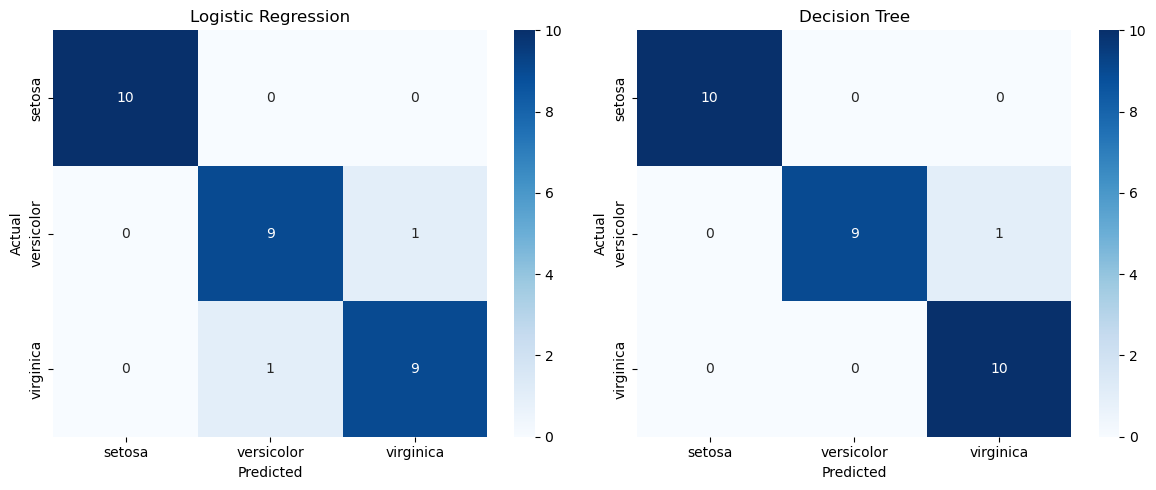

In [69]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Logistic Regression", log_predictions),
    ("Decision Tree", tree_predictions)
]

for ax, (name, predictions) in zip(axes, models):

    cm = confusion_matrix(y_test, predictions, labels=y.unique())

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=y.unique(),
        yticklabels=y.unique()
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

# Compare the two models

In [71]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],

    'Accuracy': [
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, tree_predictions)
    ],

    'Precision': [
        precision_score(y_test, log_predictions, average='macro'),
        precision_score(y_test, tree_predictions, average='macro')
    ],

    'Recall': [
        recall_score(y_test, log_predictions, average='macro'),
        recall_score(y_test, tree_predictions, average='macro')
    ],

    'F1 Score': [
        f1_score(y_test, log_predictions, average='macro'),
        f1_score(y_test, tree_predictions, average='macro')
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.966667,0.969697,0.966667,0.966583


# Precision

In [ ]:
- Logistic Regression: 93.33%
- Decision Tree: 96.97%
Precision measures how many of the flowers predicted to belong to a particular species actually belonged to that species.

Interpretation: Decision Tree had slightly higher precision, meaning its predictions were more reliable overall.

# Visualize the Decision Tree

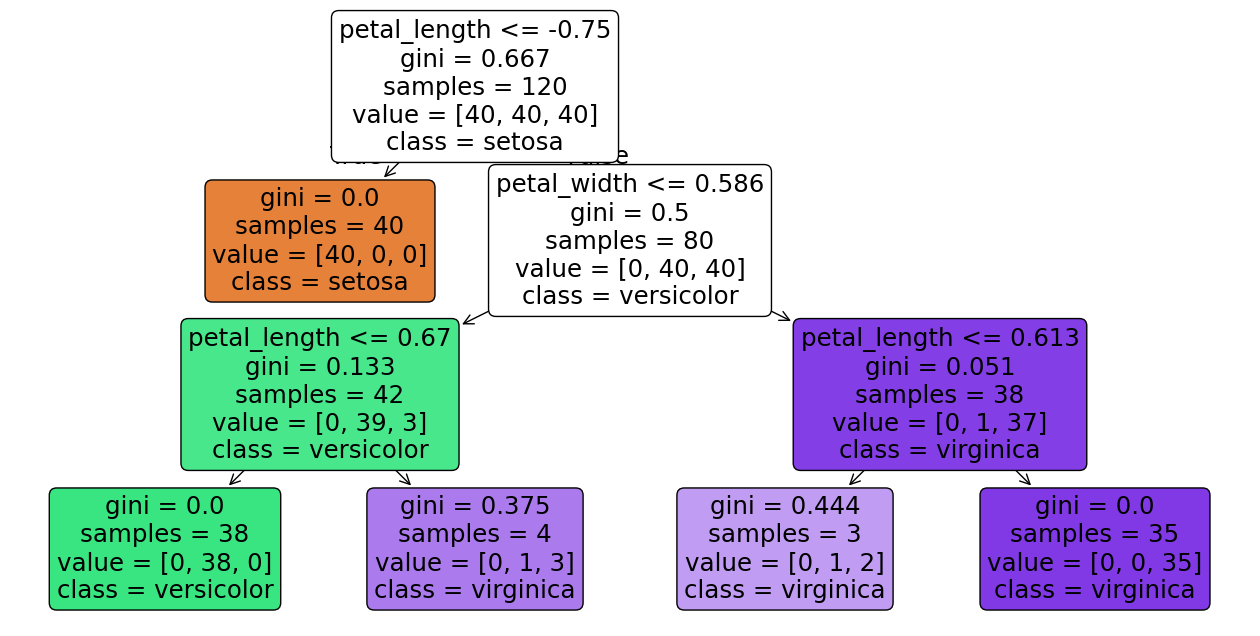

In [73]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True
)

plt.show()

In [77]:
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    log_predictions
))

print("DECISION TREE CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    tree_predictions
))

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

